# Y Combinator Companies EDA: Egypt and similar markets

Dataset #8 from the team's dataset list: Y Combinator companies (YC OSS).

**Goal:** find out what this data can answer for the project, what it can't, and what data is still needed from Egyptian companies.

- **Source:** https://yc-oss.github.io/api/companies/all.json
- **What it is:** an unofficial list of every company that went through Y Combinator, with batch, sector, location, team size and status. It is updated regularly, so the counts change over time.
- **Regions:** the project targets Egypt first, then countries with similar economies. Companies are grouped in three layers:
  1. Egypt
  2. MENA + Africa (Middle East and North Africa, and Africa)
  3. Emerging markets (layer 2 + South Asia + Latin America)

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

## 1. Load the data

In [2]:
data_dir = Path("Data")
if not data_dir.exists():
    data_dir = Path("../Data")

df = pd.read_json(data_dir / "raw" / "yc_companies_all.json")
print("Shape:", df.shape)
df.columns.tolist()

Shape: (6336, 29)


['id',
 'name',
 'slug',
 'former_names',
 'small_logo_thumb_url',
 'website',
 'all_locations',
 'long_description',
 'one_liner',
 'team_size',
 'industry',
 'subindustry',
 'launched_at',
 'tags',
 'tags_highlighted',
 'top_company',
 'isHiring',
 'nonprofit',
 'batch',
 'status',
 'industries',
 'regions',
 'stage',
 'app_video_public',
 'demo_day_video_public',
 'app_answers',
 'question_answers',
 'url',
 'api']

In [3]:
main_columns = ["name", "batch", "status", "industry", "team_size", "all_locations", "regions"]
df[main_columns].head()

,name,batch,status,industry,team_size,all_locations,regions
0,CircuitHub,Winter 2012,Active,Industrials,58.0,"London, England, United Kingdom","[United Kingdom, Europe, Remote, Partly Remote]"
1,iCracked,Winter 2012,Acquired,Consumer,51.0,"San Francisco, CA, USA; Redwood City, CA, USA","[United States of America, America / Canada]"
2,42Floors,Winter 2012,Acquired,Real Estate and Construction,60.0,"San Francisco, CA, USA; Remote","[United States of America, America / Canada, R..."
3,PlanGrid,Winter 2012,Acquired,Real Estate and Construction,355.0,"San Francisco, CA, USA","[United States of America, America / Canada]"
4,WireOver,Winter 2012,Inactive,B2B,2.0,"Boston, MA, USA; Cambridge, MA, USA","[United States of America, America / Canada]"


## 2. Basic checks

In [4]:
print("Duplicate ids:", df["id"].duplicated().sum())
print("Names used by more than one company:", df["name"].duplicated().sum())
df[df["name"].duplicated(keep=False)].sort_values("name")[["id", "name", "batch", "status"]].head(6)

Duplicate ids: 0
Names used by more than one company: 98


,id,name,batch,status
4908,30100,Alex,Fall 2024,Active
4371,29263,Alex,Winter 2024,Active
3789,27159,Almond,Summer 2022,Inactive
5128,30430,Almond,Spring 2025,Active
65,72,Apollo,Summer 2011,Active
2997,24343,Apollo,Summer 2021,Inactive


In [5]:
missing = df.isna().sum()
missing[missing > 0]

website                1
long_description      29
team_size            116
top_company            1
app_answers         6260
dtype: int64

In [6]:
print("Empty location text:", (df["all_locations"] == "").sum())
print("Empty region list:", (df["regions"].apply(len) == 0).sum())

Empty location text: 151
Empty region list: 0


In [7]:
df["status"].value_counts()

status
Active      4371
Inactive    1101
Acquired     839
Public        23
Not YC         2
Name: count, dtype: int64

In [8]:
df[df["status"] == "Not YC"][["name", "batch", "status"]]

,name,batch,status
1668,Monzo Bank,other,Not YC
1670,Convoy,other,Not YC


**Notes:**
- 6,336 companies and 29 columns. No duplicate ids.
- 98 names are used by more than one company, but they have different ids and batches, so they are different companies, not duplicates.
- Few missing values: team size (116) and long description (29). `app_answers` is almost all empty (6,260) and is not needed.
- 151 companies have no location text, but every company has a region list.
- 2 companies are marked "Not YC" (Monzo Bank and Convoy, batch "other").

## 3. Data problems

In [9]:
print("Negative team size:", (df["team_size"] < 0).sum())
print("Team size 0:", (df["team_size"] == 0).sum())
print("Team size missing:", df["team_size"].isna().sum())
df.sort_values("team_size", ascending=False)[["name", "batch", "team_size"]].head(8)

Negative team size: 1
Team size 0: 138
Team size missing: 116


,name,batch,team_size
2042,Breadfast,Summer 2019,10000.0
515,DoorDash,Summer 2013,8600.0
230,Stripe,Summer 2009,7000.0
261,Airbnb,Winter 2009,6132.0
424,Coinbase,Summer 2012,6112.0
768,EquipmentShare,Winter 2015,5400.0
2258,99minutos,Winter 2020,5000.0
1772,Deel,Winter 2019,5000.0


The batch name (for example "Winter 2016") has the year the company joined YC. There is no founding year in the data, so the batch year is the closest thing to company age.

In [10]:
df["batch_year"] = pd.to_numeric(df["batch"].str.extract(r"(\d{4})")[0])
print("Batches without a year:", df["batch_year"].isna().sum())
print(df.loc[df["batch_year"].isna(), "batch"].value_counts())
print("Batch years:", df["batch_year"].min(), "to", df["batch_year"].max())

Batches without a year: 3
batch
other          2
Unspecified    1
Name: count, dtype: int64
Batch years: 2005.0 to 2027.0


In [11]:
# launched_at looks like a date, so check if it can be used as a founding date
df["launched_year"] = pd.to_datetime(df["launched_at"], unit="s").dt.year
gap = df["launched_year"] - df["batch_year"]
print("launched_at more than 1 year after the batch:", (gap > 1).sum())
print("Latest launched_at:", pd.to_datetime(df["launched_at"], unit="s").max())

launched_at more than 1 year after the batch: 296
Latest launched_at: 2026-10-25 00:35:03


**Notes:**
- Team size: 1 company has -1 and 138 have 0, which can't be right. 116 are missing.
- The biggest team size is Breadfast (Egypt) with 10,000. This round number is bigger than DoorDash (8,600) and Stripe (7,000), so it may be an estimate.
- There is no founding year. The batch year (2005 to 2027) is used instead. 3 companies have no year in their batch.
- `launched_at` is not a founding date: 296 companies have it more than a year after their batch, and the latest one is from the same day the file was downloaded.

## 4. Region layers

In [12]:
mena_africa = ["Middle East and North Africa", "Africa"]
emerging = mena_africa + ["South Asia", "Latin America"]

df["egypt"] = df["regions"].apply(lambda regions: "Egypt" in regions)
df["mena_africa"] = df["regions"].apply(lambda regions: any(r in mena_africa for r in regions))
df["emerging"] = df["regions"].apply(lambda regions: any(r in emerging for r in regions))

layers = {
    "Egypt": df["egypt"],
    "MENA + Africa": df["mena_africa"],
    "Emerging markets": df["emerging"],
    "All YC": pd.Series(True, index=df.index),
}
pd.Series({name: mask.sum() for name, mask in layers.items()}, name="companies")

Egypt                 14
MENA + Africa        171
Emerging markets     627
All YC              6336
Name: companies, dtype: int64

## 5. The Egyptian companies

In [13]:
egypt = df[df["egypt"]]
egypt[["name", "batch", "status", "industry", "team_size", "all_locations"]]

,name,batch,status,industry,team_size,all_locations
977,Luciq (formerly Instabug),Winter 2016,Active,B2B,250.0,"Cairo, Cairo Governorate, Egypt"
988,Lynks,Winter 2016,Active,Consumer,40.0,"Cairo, Cairo Governorate, Egypt; Alexandria Go..."
2009,Trella,Summer 2019,Active,B2B,50.0,"Cairo, Cairo Governorate, Egypt"
2042,Breadfast,Summer 2019,Active,Consumer,10000.0,"Cairo, Cairo Governorate, Egypt"
2229,Thndr,Summer 2020,Active,Fintech,235.0,"Cairo, Cairo Governorate, Egypt"
2252,Sakneen,Winter 2020,Active,Real Estate and Construction,9.0,"Cairo, Cairo Governorate, Egypt; Remote"
2650,Flextock,Winter 2021,Active,B2B,10.0,"Cairo, Cairo Governorate, Egypt"
2751,Dayra,Winter 2021,Active,Fintech,10.0,"Cairo, Cairo Governorate, Egypt"
2753,peopleCQ,Winter 2021,Active,Fintech,85.0,"Cairo, Cairo Governorate, Egypt"
3024,ShipBlu,Summer 2021,Active,B2B,300.0,"Cairo, Cairo Governorate, Egypt"


**Notes:**
- Only 14 Egyptian companies, from 2016 to 2026. 13 are Active and 1 (Skillza) is Inactive.
- Sectors: B2B (6), Fintech (4), Consumer (2), Real Estate (1), Education (1). All 14 list Cairo as a location.
- They include some of the best-known Egyptian startups, like Instabug (now Luciq), Breadfast, Thndr and Trella. So this is not a normal sample of Egyptian startups. It is mostly the successful ones.

## 6. Status by layer (%)

In [14]:
status_by_layer = pd.DataFrame(
    {name: df.loc[mask, "status"].value_counts(normalize=True) * 100 for name, mask in layers.items()}
)
status_by_layer.fillna(0).round(1)

,Egypt,MENA + Africa,Emerging markets,All YC
status,,,,
Acquired,0.0,7.0,7.8,13.2
Active,92.9,80.7,75.6,69.0
Inactive,7.1,12.3,16.3,17.4
Not YC,0.0,0.0,0.0,0.0
Public,0.0,0.0,0.3,0.4


## 7. Does status depend on company age?

Older companies have had more time to close or be acquired. If that is true, the status of young and old companies can't be compared directly.

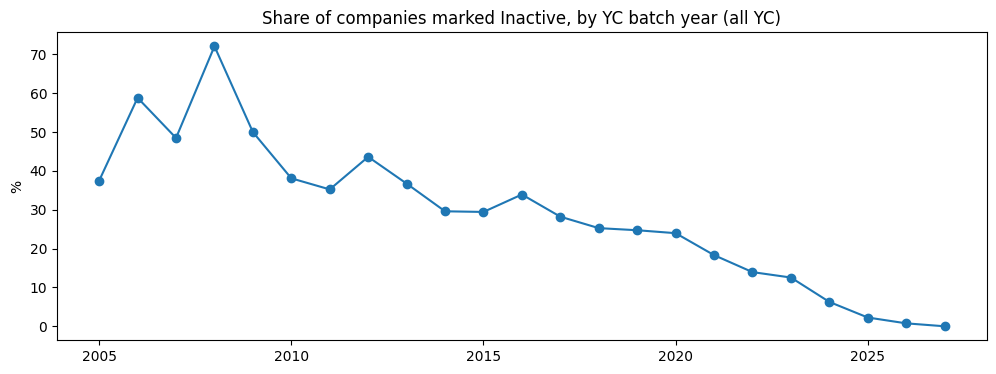

In [15]:
inactive_by_year = (df["status"] == "Inactive").groupby(df["batch_year"]).mean() * 100

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(inactive_by_year.index, inactive_by_year.values, marker="o")
ax.set_title("Share of companies marked Inactive, by YC batch year (all YC)")
ax.set_ylabel("%")
plt.show()

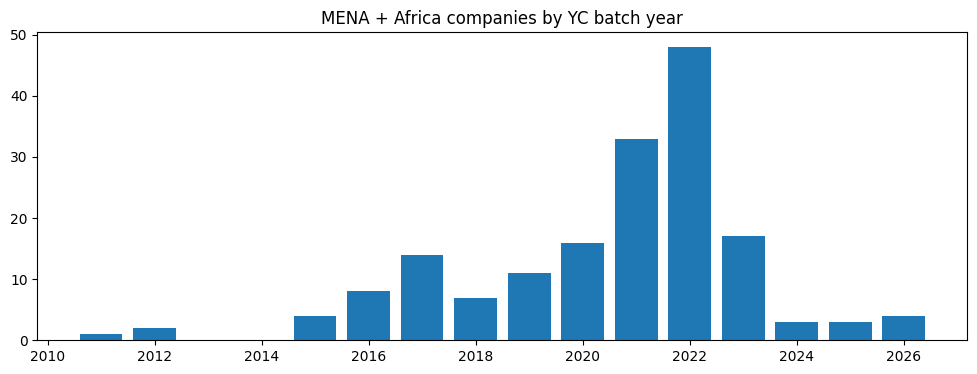

In [16]:
regional_years = df.loc[df["mena_africa"], "batch_year"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(regional_years.index, regional_years.values)
ax.set_title("MENA + Africa companies by YC batch year")
plt.show()

In [17]:
# Compare only companies from the same batch years, so age is similar
same_years = df[df["batch_year"].between(2017, 2023)]
pd.crosstab(same_years["mena_africa"], same_years["status"], normalize="index").mul(100).round(1)

status,Acquired,Active,Inactive,Public
mena_africa,,,,
False,14.3,65.8,19.7,0.1
True,4.8,81.5,13.7,0.0


**Notes:**
- By layer, Egypt has 92.9% Active, MENA + Africa 80.7%, and all YC 69.0%. At first the region looks healthier.
- The Inactive share drops a lot with batch year: 72% for 2008, about 25% for 2018 to 2020, and 2% for 2025. Older companies had more time to close, so status depends on age.
- Most MENA + Africa companies joined in 2020 to 2022, so they are younger than the average YC company.
- But even with the same batch years (2017 to 2023), MENA + Africa has fewer Inactive companies (13.7% vs 19.7%) and far fewer acquisitions (4.8% vs 14.3%). The data can't say why. One possible reason is that small companies outside the US are updated less often in this list.
- "Inactive" has no date, and it may not always mean the company closed.

## 8. Industries

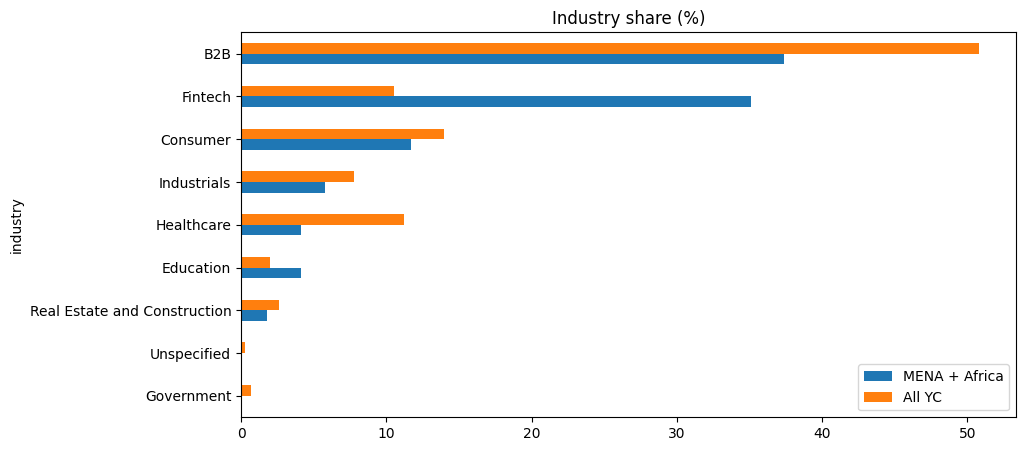

,MENA + Africa,All YC
industry,,
B2B,37.4,50.8
Fintech,35.1,10.5
Consumer,11.7,14.0
Industrials,5.8,7.8
Education,4.1,2.0
Healthcare,4.1,11.2
Real Estate and Construction,1.8,2.6
Government,0.0,0.7
Unspecified,0.0,0.3


In [18]:
industry_share = pd.DataFrame(
    {
        "MENA + Africa": df.loc[df["mena_africa"], "industry"].value_counts(normalize=True) * 100,
        "All YC": df["industry"].value_counts(normalize=True) * 100,
    }
).fillna(0).round(1)
industry_share = industry_share.sort_values("MENA + Africa")

industry_share.plot(kind="barh", figsize=(10, 5), title="Industry share (%)")
plt.show()
industry_share.sort_values("MENA + Africa", ascending=False)

**Notes:**
- Fintech is 35.1% of MENA + Africa companies, compared with 10.5% in all YC.
- B2B (37.4% vs 50.8%) and Healthcare (4.1% vs 11.2%) are lower in the region.
- Fintech being this big fits the README example question about the Egyptian FinTech market.

## 9. Team size by layer

In [19]:
pd.DataFrame(
    {name: df.loc[mask, "team_size"].describe() for name, mask in layers.items()}
).round(1)

,Egypt,MENA + Africa,Emerging markets,All YC
count,14.0,166.0,620.0,6220.0
mean,796.5,125.5,119.5,47.5
std,2650.8,785.4,576.0,311.1
min,5.0,0.0,0.0,-1.0
25%,12.5,8.0,9.0,2.0
50%,57.5,19.0,20.0,6.0
75%,197.5,60.0,55.2,19.0
max,10000.0,10000.0,10000.0,10000.0


**Notes:**
- Median team size: Egypt 57.5, MENA + Africa 19, all YC 6. The Egyptian YC companies are much bigger than a typical YC company.
- The means are pulled up by a few huge companies (up to 10,000), so the median is the better number here.
- Team size is today's size, not the size when the company started.

## 10. Save the regional table

In [20]:
regional = df[df["emerging"]][
    ["name", "batch", "batch_year", "status", "industry", "subindustry", "team_size",
     "all_locations", "egypt", "mena_africa", "website", "url"]
]
regional_path = data_dir / "processed" / "yc_emerging_markets_companies.csv"
regional.to_csv(regional_path, index=False)
print("Saved", regional_path, regional.shape)

Saved ..\Data\processed\yc_emerging_markets_companies.csv (627, 12)


## 11. What kind of data is this?

- A list of companies, one row per company, taken from the YC website by an unofficial project (yc-oss).
- It shows each company as it is today. There is no history, no closing dates, no funding amounts and no revenue.
- It only has YC companies, a small group that got into a top accelerator. It is not a normal sample of startups.
- It changes over time: 6,336 companies here, 6,279 in the team's 8 October list.

## 12. What questions can it answer?

The first 8 questions come from the project README. The last 2 are specific to this dataset.

| # | Question | Answer | Why |
|---|---|---|---|
| 1 | What is this startup's failure risk in the next 12 or 24 months? | No | Status is only today's state, with no dates. "Inactive" may not mean closed. |
| 2 | How likely is it to survive 1, 2, 3 or 5 years? | No | No founding or closing dates. The batch year only gives a rough age. |
| 3 | Does its growth rate make sense for its sector? | No | No revenue or customer numbers, only today's team size. |
| 4 | What happens to cash runway if expenses drop 20 to 25%? | No | No financial data. |
| 5 | How would a currency devaluation or inflation affect the company? | No | No financial data or currency exposure. |
| 6 | How is the Egyptian market doing? What are funding conditions? | Partly | Shows which sectors regional YC companies are in (Fintech 35%). No funding amounts. |
| 7 | How does my startup compare with its sector? | Partly | Can list similar YC companies by sector and region, but only with name, sector, team size and status. |
| 8 | Why is the risk high? Which factors matter? | No | No outcome label or model. |
| 9 | How many YC companies are from Egypt and the region, and in which sectors? | Yes | Sections 4, 5 and 8. |
| 10 | Does "Inactive" depend on company age? | Yes | Section 7: older batches have many more Inactive companies. |

## 13. How it can help the project

- A list of known Egyptian and regional startups to use as examples in RAG answers and the demo, for example "similar Fintech companies in the region: Thndr, Dayra, Amenli".
- A quick way to find similar companies by sector and region (question 7).
- A list of Egyptian startups the team could contact for the company interviews.
- It should not be used to train a failure model: the label is unclear, there are no dates, and there are only 14 Egyptian companies.

The regional table (627 companies) is saved in `Data/processed/yc_emerging_markets_companies.csv`.

## 14. What data is still needed

**To ask Egyptian companies:**
- Founding date, and closing date if the company closed.
- Monthly revenue, costs and cash.
- Funding rounds: amount and date.
- Number of customers, and how it changed over time.
- Team size over time, not only today.

**From other sources:**
- A list of Egyptian startups outside YC, including ones that closed. Most Egyptian startups never join YC.
- Funding data for Egypt and the region (question 6).